In [1]:
from Utils.Utils import load_covertype_data

X, y = load_covertype_data()

print("X shape:", X.shape)
print("y shape:", y.shape)

Loading local dataset from 'c:\Users\julia\Desktop\Academics\CENTRALE 3A\CE\DAML\DAML-Forest-Cover-Type-Classification\DATA\raw'
Filtering the dataset based on active features...
X shape: (581012, 54)
y shape: (581012, 1)


In [ ]:
from Utils.Utils import (
    PreprocessingConfig,
    build_preprocessor
)
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

config = PreprocessingConfig(
    scaling=False,
    pca="none"
)


model = RandomForestClassifier(
    n_estimators=20,       # Start with 20 trees instead of 100
    max_depth=15,          # Limit how deep each tree can grow
    min_samples_leaf=5,    # Require at least 5 samples per leaf
    random_state=42,
    n_jobs=1               # Use one CPU worker to reduce memory pressure
)


In [3]:

from Utils.Utils import load_covertype_data, split_data

X, y = load_covertype_data()

X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)


Loading local dataset from 'c:\Users\julia\Desktop\Academics\CENTRALE 3A\CE\DAML\DAML-Forest-Cover-Type-Classification\DATA\raw'
Filtering the dataset based on active features...
Training set: (406708, 54)
Validation set: (87152, 54)
Test set: (87152, 54)


In [4]:

model.fit(X_train, y_train.squeeze())

predictions = model.predict(X_val)

print("Training complete!")
print("Predictions:", predictions.shape)


Training complete!
Predictions: (87152,)


In [5]:

from sklearn.metrics import accuracy_score, classification_report

y_val_true = y_val.squeeze()

accuracy = accuracy_score(y_val_true, predictions)

print(f"Validation accuracy: {accuracy:.4f}")
print(f"Validation accuracy: {accuracy * 100:.2f}%")

print("\nClassification report:")
print(classification_report(y_val_true, predictions))


Validation accuracy: 0.8214
Validation accuracy: 82.14%

Classification report:
              precision    recall  f1-score   support

           1       0.83      0.78      0.80     31776
           2       0.80      0.89      0.85     42495
           3       0.84      0.89      0.86      5363
           4       0.89      0.70      0.78       412
           5       0.95      0.17      0.30      1424
           6       0.89      0.52      0.65      2605
           7       0.95      0.74      0.83      3077

    accuracy                           0.82     87152
   macro avg       0.88      0.67      0.72     87152
weighted avg       0.83      0.82      0.82     87152



In [6]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

balanced_model = RandomForestClassifier(
    n_estimators=20,
    max_depth=15,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=1
)

balanced_model.fit(X_train, y_train.squeeze())

balanced_predictions = balanced_model.predict(X_val)

print(f"Validation accuracy: {accuracy_score(y_val.squeeze(), balanced_predictions):.2%}")
print(classification_report(y_val.squeeze(), balanced_predictions))


Validation accuracy: 78.60%
              precision    recall  f1-score   support

           1       0.80      0.82      0.81     31776
           2       0.89      0.73      0.80     42495
           3       0.81      0.84      0.83      5363
           4       0.62      0.95      0.75       412
           5       0.25      0.94      0.40      1424
           6       0.56      0.89      0.69      2605
           7       0.72      0.97      0.83      3077

    accuracy                           0.79     87152
   macro avg       0.67      0.88      0.73     87152
weighted avg       0.82      0.79      0.80     87152



In [7]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train.squeeze())

# Calculate balanced weights, then soften their effect.
balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.squeeze()
)

soft_weights = balanced_weights ** 0.5
class_weights = dict(zip(classes, soft_weights))

compromise_model = RandomForestClassifier(
    n_estimators=20,
    max_depth=15,
    min_samples_leaf=5,
    class_weight=class_weights,
    random_state=42,
    n_jobs=1
)

compromise_model.fit(X_train, y_train.squeeze())
compromise_predictions = compromise_model.predict(X_val)

print(
    f"Validation accuracy: "
    f"{accuracy_score(y_val.squeeze(), compromise_predictions):.2%}"
)
print(classification_report(y_val.squeeze(), compromise_predictions))


Validation accuracy: 83.07%
              precision    recall  f1-score   support

           1       0.82      0.80      0.81     31776
           2       0.84      0.85      0.85     42495
           3       0.85      0.90      0.88      5363
           4       0.78      0.88      0.82       412
           5       0.72      0.61      0.66      1424
           6       0.74      0.82      0.78      2605
           7       0.87      0.90      0.89      3077

    accuracy                           0.83     87152
   macro avg       0.80      0.82      0.81     87152
weighted avg       0.83      0.83      0.83     87152



In [ ]:
### With preprocessing (scaling only)

import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
from sklearn.pipeline import Pipeline

from Utils.Utils import build_preprocessor, PreprocessingConfig


# 1. Calculate softened class weights (same as before)
classes = np.unique(y_train.squeeze())

balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.squeeze()
)

soft_weights = balanced_weights ** 0.5

class_weights = dict(zip(classes, soft_weights))


# 2. Configure preprocessing
preprocessing_config = PreprocessingConfig(
    scaling=True,       # Apply feature scaling
    pca="none"          # Do not apply PCA
)

preprocessor = build_preprocessor(preprocessing_config)


# 3. Define the same Random Forest model as before
random_forest = RandomForestClassifier(
    n_estimators=20,
    max_depth=15,
    min_samples_leaf=5,
    class_weight=class_weights,
    random_state=42,
    n_jobs=1
)


# 4. Combine preprocessing and model into one pipeline
model_with_preprocessing = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", random_forest)
])


# 5. Train on the training set
model_with_preprocessing.fit(
    X_train,
    y_train.squeeze()
)


# 6. Predict on the validation set
preprocessed_predictions = model_with_preprocessing.predict(X_val)


# 7. Evaluate the results
print("Validation accuracy:",
      accuracy_score(y_val.squeeze(), preprocessed_predictions))

print("\nClassification report:")
print(
    classification_report(
        y_val.squeeze(),
        preprocessed_predictions
    )
)

Validation accuracy: 0.8308013585459886

Classification report:
              precision    recall  f1-score   support

           1       0.82      0.80      0.81     31776
           2       0.84      0.85      0.85     42495
           3       0.85      0.90      0.88      5363
           4       0.78      0.88      0.82       412
           5       0.72      0.61      0.66      1424
           6       0.74      0.82      0.78      2605
           7       0.87      0.90      0.89      3077

    accuracy                           0.83     87152
   macro avg       0.80      0.82      0.81     87152
weighted avg       0.83      0.83      0.83     87152



In [ ]:
### With preprocessing (scaling & PCA = "numeric")

import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
from sklearn.pipeline import Pipeline

from Utils.Utils import build_preprocessor, PreprocessingConfig


# 1. Calculate softened class weights (same as before)
classes = np.unique(y_train.squeeze())

balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.squeeze()
)

soft_weights = balanced_weights ** 0.5

class_weights = dict(zip(classes, soft_weights))


# 2. Configure preprocessing
preprocessing_config = PreprocessingConfig(
    scaling=True,       # Apply feature scaling
    pca="numeric",
    pca_components=0.95        # Do not apply PCA
)

preprocessor = build_preprocessor(preprocessing_config)


# 3. Define the same Random Forest model as before
random_forest = RandomForestClassifier(
    n_estimators=20,
    max_depth=15,
    min_samples_leaf=5,
    class_weight=class_weights,
    random_state=42,
    n_jobs=1
)


# 4. Combine preprocessing and model into one pipeline
model_with_preprocessing = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", random_forest)
])


# 5. Train on the training set
model_with_preprocessing.fit(
    X_train,
    y_train.squeeze()
)


# 6. Predict on the validation set
preprocessed_predictions = model_with_preprocessing.predict(X_val)


# 7. Evaluate the results
print("Validation accuracy:",
      accuracy_score(y_val.squeeze(), preprocessed_predictions))

print("\nClassification report:")
print(
    classification_report(
        y_val.squeeze(),
        preprocessed_predictions
    )
)

Validation accuracy: 0.797663851661465

Classification report:
              precision    recall  f1-score   support

           1       0.80      0.76      0.78     31776
           2       0.81      0.83      0.82     42495
           3       0.79      0.85      0.82      5363
           4       0.69      0.81      0.75       412
           5       0.68      0.49      0.57      1424
           6       0.64      0.66      0.65      2605
           7       0.81      0.84      0.83      3077

    accuracy                           0.80     87152
   macro avg       0.75      0.75      0.74     87152
weighted avg       0.80      0.80      0.80     87152



In [12]:
### With preprocessing (scaling & PCA = "all")

import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight
from sklearn.pipeline import Pipeline

from Utils.Utils import build_preprocessor, PreprocessingConfig


# 1. Calculate softened class weights (same as before)
classes = np.unique(y_train.squeeze())

balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.squeeze()
)

soft_weights = balanced_weights ** 0.5

class_weights = dict(zip(classes, soft_weights))


# 2. Configure preprocessing
preprocessing_config = PreprocessingConfig(
    scaling=True,       # Apply feature scaling
    pca="all",
    pca_components=0.95        # Do not apply PCA
)

preprocessor = build_preprocessor(preprocessing_config)


# 3. Define the same Random Forest model as before
random_forest = RandomForestClassifier(
    n_estimators=20,
    max_depth=15,
    min_samples_leaf=5,
    class_weight=class_weights,
    random_state=42,
    n_jobs=1
)


# 4. Combine preprocessing and model into one pipeline
model_with_preprocessing = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", random_forest)
])


# 5. Train on the training set
model_with_preprocessing.fit(
    X_train,
    y_train.squeeze()
)


# 6. Predict on the validation set
preprocessed_predictions = model_with_preprocessing.predict(X_val)


# 7. Evaluate the results
print("Validation accuracy:",
      accuracy_score(y_val.squeeze(), preprocessed_predictions))

print("\nClassification report:")
print(
    classification_report(
        y_val.squeeze(),
        preprocessed_predictions
    )
)

Validation accuracy: 0.8443409216082247

Classification report:
              precision    recall  f1-score   support

           1       0.86      0.80      0.83     31776
           2       0.85      0.88      0.87     42495
           3       0.84      0.89      0.86      5363
           4       0.80      0.81      0.81       412
           5       0.69      0.68      0.69      1424
           6       0.69      0.82      0.75      2605
           7       0.81      0.91      0.86      3077

    accuracy                           0.84     87152
   macro avg       0.79      0.83      0.81     87152
weighted avg       0.85      0.84      0.84     87152



In [14]:
### With preprocessing (aspect transformer only)

import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, f1_score

from Utils.Utils import build_preprocessor, PreprocessingConfig


# Keep the same class_weights dictionary from your previous experiment
# and the same X_train, X_val, y_train, y_val split.

def run_aspect_experiment(cyclic_aspect):
    config = PreprocessingConfig(
        scaling=False,
        pca="none",
        cyclic_aspect=cyclic_aspect
    )

    preprocessor = build_preprocessor(config)

    rf = RandomForestClassifier(
        n_estimators=20,
        max_depth=15,
        min_samples_leaf=5,
        class_weight=class_weights,
        random_state=42,
        n_jobs=1
    )

    model = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", rf)
    ])

    model.fit(X_train, y_train.squeeze())
    predictions = model.predict(X_val)

    accuracy = accuracy_score(y_val.squeeze(), predictions)
    macro_f1 = f1_score(
        y_val.squeeze(),
        predictions,
        average="macro"
    )

    print(f"\nCyclic Aspect: {cyclic_aspect}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1:  {macro_f1:.4f}")
    print("\nClassification report:")
    print(classification_report(y_val.squeeze(), predictions))

    return model, accuracy, macro_f1


# Experiment A: Original Aspect feature
model_original, acc_original, f1_original = run_aspect_experiment(False)

# Experiment B: Aspect transformed into sine and cosine
model_cyclic, acc_cyclic, f1_cyclic = run_aspect_experiment(True)


Cyclic Aspect: False
Accuracy: 0.8307
Macro F1:  0.8109

Classification report:
              precision    recall  f1-score   support

           1       0.82      0.80      0.81     31776
           2       0.84      0.85      0.85     42495
           3       0.85      0.90      0.88      5363
           4       0.78      0.88      0.82       412
           5       0.72      0.61      0.66      1424
           6       0.74      0.82      0.78      2605
           7       0.87      0.90      0.89      3077

    accuracy                           0.83     87152
   macro avg       0.80      0.82      0.81     87152
weighted avg       0.83      0.83      0.83     87152


Cyclic Aspect: True
Accuracy: 0.8265
Macro F1:  0.8021

Classification report:
              precision    recall  f1-score   support

           1       0.82      0.80      0.81     31776
           2       0.84      0.84      0.84     42495
           3       0.85      0.89      0.87      5363
           4       0.75  

In [15]:
### With preprocessing (aspect transformer & pca = all)

import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, f1_score

from Utils.Utils import build_preprocessor, PreprocessingConfig


# 1. Configure preprocessing: scaling + PCA on all features + cyclic Aspect
config = PreprocessingConfig(
    scaling=True,
    pca="all",
    pca_components=0.95,
    cyclic_aspect=True
)

preprocessor = build_preprocessor(config)


# 2. Keep the same Random Forest parameters
random_forest = RandomForestClassifier(
    n_estimators=20,
    max_depth=15,
    min_samples_leaf=5,
    class_weight=class_weights,
    random_state=42,
    n_jobs=1
)


# 3. Create the pipeline
pca_aspect_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", random_forest)
])


# 4. Train the model
pca_aspect_model.fit(
    X_train,
    y_train.squeeze()
)


# 5. Predict on the validation set
pca_aspect_predictions = pca_aspect_model.predict(X_val)


# 6. Evaluate
print(
    "Validation accuracy:",
    accuracy_score(y_val.squeeze(), pca_aspect_predictions)
)

print("\nClassification report:")
print(
    classification_report(
        y_val.squeeze(),
        pca_aspect_predictions
    )
)

print(
    "Macro F1:",
    f1_score(
        y_val.squeeze(),
        pca_aspect_predictions,
        average="macro"
    )
)

Validation accuracy: 0.8331994675968423

Classification report:
              precision    recall  f1-score   support

           1       0.86      0.76      0.81     31776
           2       0.83      0.88      0.86     42495
           3       0.83      0.90      0.86      5363
           4       0.80      0.80      0.80       412
           5       0.69      0.67      0.68      1424
           6       0.70      0.80      0.75      2605
           7       0.82      0.91      0.86      3077

    accuracy                           0.83     87152
   macro avg       0.79      0.82      0.80     87152
weighted avg       0.83      0.83      0.83     87152

Macro F1: 0.8021888654309354


# TESTS SOLAL 

In [6]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from time import perf_counter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.pipeline import Pipeline

from Utils.Utils import (
    load_covertype_data,
    split_data,
    PreprocessingConfig,
    build_preprocessor,
)

# Same split as Julia's notebook
X, y = load_covertype_data()
X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y)

y_train = np.asarray(y_train).ravel()
y_val = np.asarray(y_val).ravel()
y_test = np.asarray(y_test).ravel()

# Class weights: w_k = (N / (K * N_k)) ** alpha
classes = np.unique(y_train)

balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

def get_class_weights(alpha):
    if alpha == 0:
        return None
    return dict(zip(classes, balanced_weights ** alpha))

# Stratified subset for initial hyperparameter search
X_bench, _, y_bench, _ = train_test_split(
    X_train,
    y_train,
    train_size=120_000,
    stratify=y_train,
    random_state=42
)

print("Benchmark training:", X_bench.shape)
print("Full training:", X_train.shape)
print("Validation:", X_val.shape)


Loading local dataset from 'c:\Users\PC GAMER\Documents\Work\Centrale_Control_Mention\DAML\DAML-Forest-Cover-Type-Classification\DATA\raw'
Filtering the dataset based on active features...
Benchmark training: (120000, 54)
Full training: (406708, 54)
Validation: (87152, 54)


In [7]:

from sklearn.model_selection import ParameterSampler

# Fixed configurations: baseline + stronger forests
configs = [
    dict(n_estimators=20, max_depth=15, min_samples_leaf=5,
         max_features="sqrt", alpha=0.5),

    dict(n_estimators=100, max_depth=25, min_samples_leaf=2,
         max_features="sqrt", alpha=0.5),

    dict(n_estimators=150, max_depth=None, min_samples_leaf=1,
         max_features="sqrt", alpha=0.5),

    dict(n_estimators=100, max_depth=25, min_samples_leaf=2,
         max_features="sqrt", alpha=0.0),

    dict(n_estimators=100, max_depth=25, min_samples_leaf=2,
         max_features="sqrt", alpha=1.0),
]

# Additional random configurations
param_space = {
    "n_estimators": [50, 100, 150],
    "max_depth": [15, 25, 40, None],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", 0.5],
    "alpha": [0, 0.25, 0.5, 0.75, 1],
}

configs += list(ParameterSampler(
    param_space,
    n_iter=7,
    random_state=42
))

results = []

for i, params in enumerate(configs, start=1):
    print(f"[{i}/{len(configs)}] {params}", flush=True)

    rf = RandomForestClassifier(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
        min_samples_leaf=params["min_samples_leaf"],
        max_features=params["max_features"],
        class_weight=get_class_weights(params["alpha"]),
        random_state=42,
        n_jobs=-1
    )

    start = perf_counter()
    rf.fit(X_bench, y_bench)
    train_time = perf_counter() - start

    start = perf_counter()
    predictions = rf.predict(X_val)
    predict_time = perf_counter() - start

    results.append({
        "experiment": i,
        **params,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val, predictions, average="macro"
        ),
        "weighted_f1": f1_score(
            y_val, predictions, average="weighted"
        ),
        "train_time": train_time,
        "predict_time": predict_time,
    })

    print(
        f"  Accuracy: {results[-1]['accuracy']:.4f} | "
        f"Macro F1: {results[-1]['macro_f1']:.4f} | "
        f"Train: {train_time:.1f}s"
    )

benchmark_df = (
    pd.DataFrame(results)
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(benchmark_df.round(4))


[1/12] {'n_estimators': 20, 'max_depth': 15, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'alpha': 0.5}


  Accuracy: 0.8121 | Macro F1: 0.7768 | Train: 0.2s
[2/12] {'n_estimators': 100, 'max_depth': 25, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'alpha': 0.5}
  Accuracy: 0.8976 | Macro F1: 0.8646 | Train: 1.0s
[3/12] {'n_estimators': 150, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'alpha': 0.5}
  Accuracy: 0.9191 | Macro F1: 0.8814 | Train: 1.5s
[4/12] {'n_estimators': 100, 'max_depth': 25, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'alpha': 0.0}
  Accuracy: 0.8896 | Macro F1: 0.8232 | Train: 1.0s
[5/12] {'n_estimators': 100, 'max_depth': 25, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'alpha': 1.0}
  Accuracy: 0.8761 | Macro F1: 0.8381 | Train: 0.7s
[6/12] {'n_estimators': 150, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 15, 'alpha': 0.75}
  Accuracy: 0.8121 | Macro F1: 0.7737 | Train: 1.0s
[7/12] {'n_estimators': 50, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 40, 'alpha': 0}
  Accuracy: 0.8822 | Macro F1: 0.7927 | Train:

,experiment,n_estimators,max_depth,min_samples_leaf,max_features,alpha,accuracy,macro_f1,weighted_f1,train_time,predict_time
0,3,150,NaN,1,sqrt,0.50,0.9191,0.8814,0.9188,1.5008,0.2179
1,11,150,NaN,1,sqrt,0.75,0.9138,0.8777,0.9137,1.3078,0.1977
2,2,100,25.0,2,sqrt,0.50,0.8976,0.8646,0.8974,0.9842,0.1453
3,10,150,NaN,1,sqrt,0.00,0.9183,0.8643,0.9174,1.4530,0.2297
4,8,50,NaN,5,0.5,0.75,0.9033,0.8620,0.9039,0.9842,0.0796
5,5,100,25.0,2,sqrt,1.00,0.8761,0.8381,0.8773,0.7005,0.1321
6,4,100,25.0,2,sqrt,0.00,0.8896,0.8232,0.8875,0.9694,0.1337
7,7,50,40.0,5,sqrt,0.00,0.8822,0.7927,0.8796,0.5268,0.0793
8,12,50,15.0,5,0.5,0.00,0.8558,0.7778,0.8527,1.0118,0.0694
9,1,20,15.0,5,sqrt,0.50,0.8121,0.7768,0.8118,0.2244,0.0509


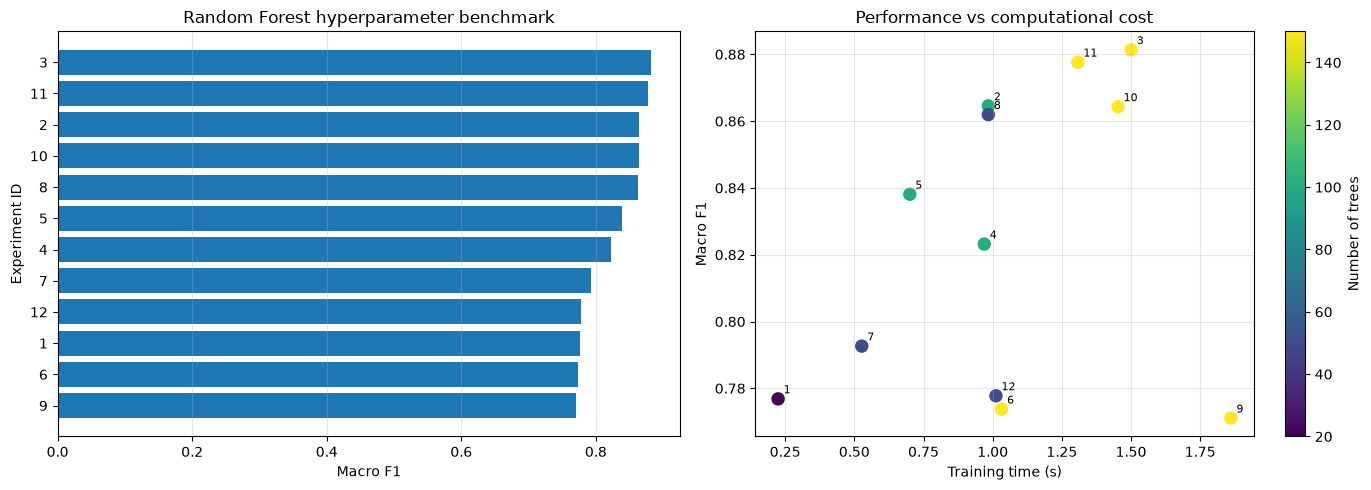

Top 5 configurations:


,experiment,n_estimators,max_depth,min_samples_leaf,max_features,alpha,accuracy,macro_f1,weighted_f1,train_time,predict_time
0,3,150,NaN,1,sqrt,0.50,0.9191,0.8814,0.9188,1.5008,0.2179
1,11,150,NaN,1,sqrt,0.75,0.9138,0.8777,0.9137,1.3078,0.1977
2,2,100,25.0,2,sqrt,0.50,0.8976,0.8646,0.8974,0.9842,0.1453
3,10,150,NaN,1,sqrt,0.00,0.9183,0.8643,0.9174,1.4530,0.2297
4,8,50,NaN,5,0.5,0.75,0.9033,0.8620,0.9039,0.9842,0.0796


In [8]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Macro F1 ranking
ranked = benchmark_df.sort_values("macro_f1")

axes[0].barh(
    ranked["experiment"].astype(str),
    ranked["macro_f1"]
)
axes[0].set_xlabel("Macro F1")
axes[0].set_ylabel("Experiment ID")
axes[0].set_title("Random Forest hyperparameter benchmark")
axes[0].grid(axis="x", alpha=0.3)

# Performance versus training time
scatter = axes[1].scatter(
    benchmark_df["train_time"],
    benchmark_df["macro_f1"],
    c=benchmark_df["n_estimators"],
    cmap="viridis",
    s=75
)

for _, row in benchmark_df.iterrows():
    axes[1].annotate(
        str(int(row["experiment"])),
        (row["train_time"], row["macro_f1"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

axes[1].set_xlabel("Training time (s)")
axes[1].set_ylabel("Macro F1")
axes[1].set_title("Performance vs computational cost")
axes[1].grid(alpha=0.3)

fig.colorbar(
    scatter, ax=axes[1],
    label="Number of trees"
)

plt.tight_layout()
plt.show()

print("Top 5 configurations:")
display(benchmark_df.head(5).round(4))


Training full model 3...
Training full model 11...
Training full model 2...


,experiment,accuracy,macro_f1,train_time
0,3,0.9527,0.9276,8.7382
1,11,0.9498,0.9264,7.4124
2,2,0.9290,0.9096,5.5755


Best model: {'n_estimators': 150, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'alpha': 0.5}
              precision    recall  f1-score   support

           1       0.96      0.94      0.95     31776
           2       0.95      0.97      0.96     42495
           3       0.93      0.96      0.95      5363
           4       0.91      0.86      0.88       412
           5       0.88      0.87      0.87      1424
           6       0.91      0.92      0.92      2605
           7       0.96      0.97      0.96      3077

    accuracy                           0.95     87152
   macro avg       0.93      0.93      0.93     87152
weighted avg       0.95      0.95      0.95     87152



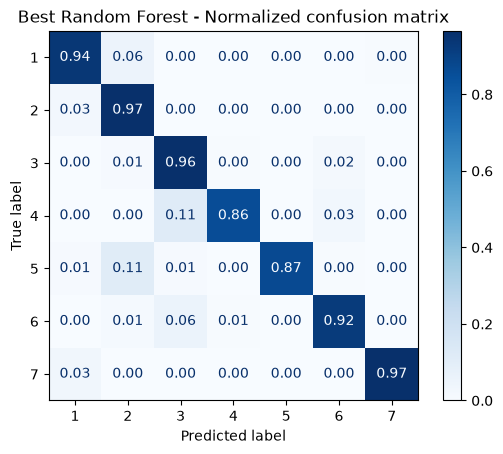

In [9]:

top_configs = benchmark_df.head(3)

final_results = []
trained_models = {}

for _, row in top_configs.iterrows():
    experiment_id = int(row["experiment"])
    params = configs[experiment_id - 1]

    print(f"Training full model {experiment_id}...", flush=True)

    model = RandomForestClassifier(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
        min_samples_leaf=params["min_samples_leaf"],
        max_features=params["max_features"],
        class_weight=get_class_weights(params["alpha"]),
        random_state=42,
        n_jobs=-1
    )

    start = perf_counter()
    model.fit(X_train, y_train)
    train_time = perf_counter() - start

    predictions = model.predict(X_val)

    final_results.append({
        "experiment": experiment_id,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val, predictions, average="macro"
        ),
        "train_time": train_time,
    })

    trained_models[experiment_id] = model

final_df = (
    pd.DataFrame(final_results)
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(final_df.round(4))

best_id = int(final_df.iloc[0]["experiment"])
best_model = trained_models[best_id]

predictions = best_model.predict(X_val)

print("Best model:", configs[best_id - 1])
print(classification_report(y_val, predictions))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    predictions,
    normalize="true",
    cmap="Blues",
    values_format=".2f"
)

plt.title("Best Random Forest - Normalized confusion matrix")
plt.show()


Testing No PCA...
Testing Numeric PCA 95%...
Testing Global PCA 95%...


,preprocessing,accuracy,macro_f1,train_time
0,No PCA,0.9527,0.9276,9.0536
1,Numeric PCA 95%,0.9282,0.8888,10.9894
2,Global PCA 95%,0.9429,0.9082,28.6180


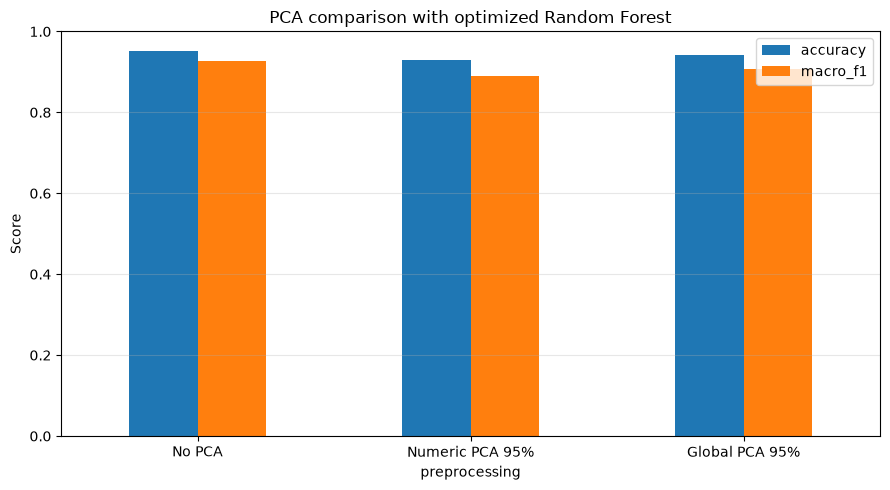

In [10]:

from sklearn.base import clone

preprocessing_configs = {
    "No PCA": PreprocessingConfig(
        scaling=False,
        pca="none"
    ),
    "Numeric PCA 95%": PreprocessingConfig(
        scaling=True,
        pca="numeric",
        pca_components=0.95
    ),
    "Global PCA 95%": PreprocessingConfig(
        scaling=True,
        pca="all",
        pca_components=0.95
    )
}

pca_results = []

for name, config in preprocessing_configs.items():
    print(f"Testing {name}...", flush=True)

    pipeline = Pipeline([
        ("preprocessing", build_preprocessor(config)),
        ("classifier", clone(best_model))
    ])

    start = perf_counter()
    pipeline.fit(X_train, y_train)
    train_time = perf_counter() - start

    predictions = pipeline.predict(X_val)

    pca_results.append({
        "preprocessing": name,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val, predictions, average="macro"
        ),
        "train_time": train_time
    })

pca_df = pd.DataFrame(pca_results)

display(pca_df.round(4))

pca_df.plot(
    x="preprocessing",
    y=["accuracy", "macro_f1"],
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.ylabel("Score")
plt.title("PCA comparison with optimized Random Forest")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Deuxièmes test

In [11]:
from itertools import product
from time import perf_counter

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# Full training data
n_estimators_values = [100, 200, 300]
max_features_values = ["sqrt", 0.5]
alpha_values = [0, 0.25, 0.5, 0.75]

rf_search_configs = [
    {
        "n_estimators": n,
        "max_features": mf,
        "alpha": alpha
    }
    for n, mf, alpha in product(
        n_estimators_values,
        max_features_values,
        alpha_values
    )
]

rf_search_results = []

for i, params in enumerate(rf_search_configs, start=1):

    model = RandomForestClassifier(
        n_estimators=params["n_estimators"],
        max_depth=None,
        min_samples_leaf=1,
        max_features=params["max_features"],
        class_weight=get_class_weights(params["alpha"]),
        random_state=42,
        n_jobs=-1
    )

    start = perf_counter()
    model.fit(X_train, y_train)
    train_time = perf_counter() - start

    start = perf_counter()
    predictions = model.predict(X_val)
    predict_time = perf_counter() - start

    result = {
        "experiment": i,
        **params,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val, predictions, average="macro"
        ),
        "weighted_f1": f1_score(
            y_val, predictions, average="weighted"
        ),
        "train_time": train_time,
        "predict_time": predict_time
    }

    rf_search_results.append(result)

    print(
        f"[{i:02d}/{len(rf_search_configs)}] "
        f"Trees={params['n_estimators']} | "
        f"Features={params['max_features']} | "
        f"Alpha={params['alpha']} | "
        f"Macro F1={result['macro_f1']:.5f} | "
        f"Time={train_time:.1f}s",
        flush=True
    )

rf_search_df = (
    pd.DataFrame(rf_search_results)
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(rf_search_df.round(5))

best_params = rf_search_df.iloc[0]

print("\nBest configuration:")
print(best_params.to_string())

best_rf = RandomForestClassifier(
    n_estimators=int(best_params["n_estimators"]),
    max_depth=None,
    min_samples_leaf=1,
    max_features=best_params["max_features"],
    class_weight=get_class_weights(best_params["alpha"]),
    random_state=42,
    n_jobs=-1
)

best_rf.fit(X_train, y_train)


[01/24] Trees=100 | Features=sqrt | Alpha=0 | Macro F1=0.91917 | Time=6.4s
[02/24] Trees=100 | Features=sqrt | Alpha=0.25 | Macro F1=0.92520 | Time=6.5s
[03/24] Trees=100 | Features=sqrt | Alpha=0.5 | Macro F1=0.92816 | Time=6.0s
[04/24] Trees=100 | Features=sqrt | Alpha=0.75 | Macro F1=0.92577 | Time=5.1s
[05/24] Trees=100 | Features=0.5 | Alpha=0 | Macro F1=0.93846 | Time=12.6s
[06/24] Trees=100 | Features=0.5 | Alpha=0.25 | Macro F1=0.94409 | Time=12.2s
[07/24] Trees=100 | Features=0.5 | Alpha=0.5 | Macro F1=0.94276 | Time=11.4s
[08/24] Trees=100 | Features=0.5 | Alpha=0.75 | Macro F1=0.93884 | Time=9.4s
[09/24] Trees=200 | Features=sqrt | Alpha=0 | Macro F1=0.92033 | Time=11.8s
[10/24] Trees=200 | Features=sqrt | Alpha=0.25 | Macro F1=0.92548 | Time=12.2s
[11/24] Trees=200 | Features=sqrt | Alpha=0.5 | Macro F1=0.92656 | Time=11.3s
[12/24] Trees=200 | Features=sqrt | Alpha=0.75 | Macro F1=0.92541 | Time=9.7s
[13/24] Trees=200 | Features=0.5 | Alpha=0 | Macro F1=0.93966 | Time=24.3s

,experiment,n_estimators,max_features,alpha,accuracy,macro_f1,weighted_f1,train_time,predict_time
0,22,300,0.5,0.25,0.96715,0.94517,0.96713,35.63680,0.40594
1,14,200,0.5,0.25,0.96713,0.94414,0.96711,24.14623,0.29427
2,6,100,0.5,0.25,0.96697,0.94409,0.96695,12.15687,0.15457
3,23,300,0.5,0.50,0.96622,0.94345,0.96624,32.60966,0.41269
4,15,200,0.5,0.50,0.96631,0.94312,0.96633,22.07440,0.28211
5,7,100,0.5,0.50,0.96572,0.94276,0.96574,11.35855,0.15342
6,21,300,0.5,0.00,0.96683,0.93998,0.96673,35.94867,0.42052
7,13,200,0.5,0.00,0.96694,0.93966,0.96685,24.29954,0.29250
8,24,300,0.5,0.75,0.96335,0.93950,0.96341,27.68530,0.40166
9,8,100,0.5,0.75,0.96294,0.93884,0.96301,9.43577,0.14343



Best configuration:
experiment             22
n_estimators          300
max_features          0.5
alpha                0.25
accuracy         0.967149
macro_f1         0.945166
weighted_f1      0.967134
train_time      35.636805
predict_time     0.405942


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{np.int64(1): np.float64(0.7911697371921986), np.int64(2): np.float64(0.7357147577131893), np.int64(3): np.float64(1.2343537256122326), np.int64(4): np.float64(2.3445059957068612), ...}"
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples 

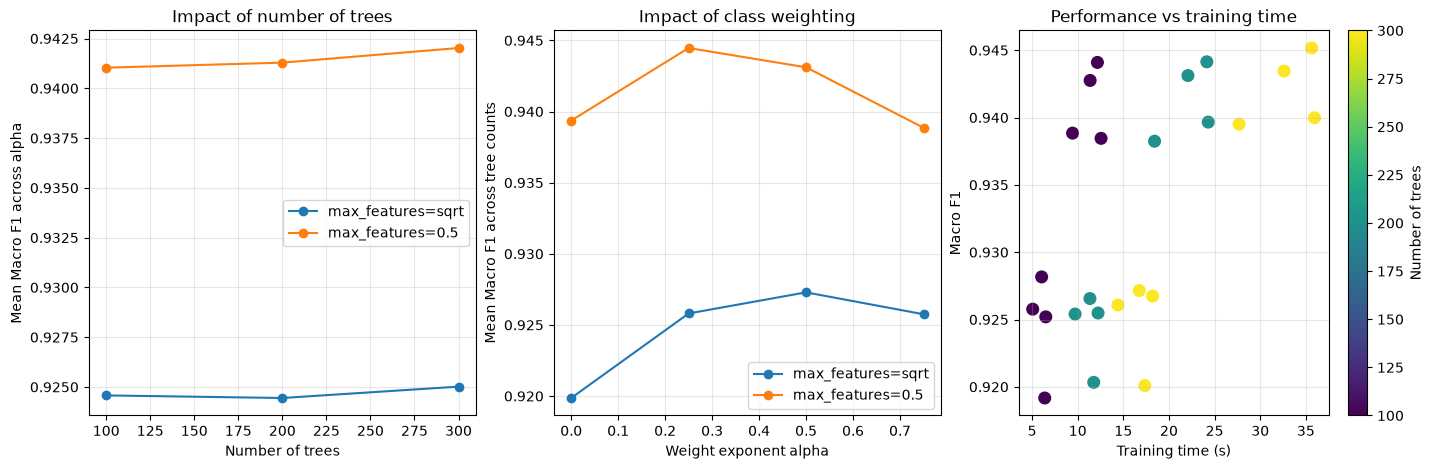

Top 10 configurations:


,experiment,n_estimators,max_features,alpha,accuracy,macro_f1,weighted_f1,train_time,predict_time
0,22,300,0.5,0.25,0.96715,0.94517,0.96713,35.63680,0.40594
1,14,200,0.5,0.25,0.96713,0.94414,0.96711,24.14623,0.29427
2,6,100,0.5,0.25,0.96697,0.94409,0.96695,12.15687,0.15457
3,23,300,0.5,0.50,0.96622,0.94345,0.96624,32.60966,0.41269
4,15,200,0.5,0.50,0.96631,0.94312,0.96633,22.07440,0.28211
5,7,100,0.5,0.50,0.96572,0.94276,0.96574,11.35855,0.15342
6,21,300,0.5,0.00,0.96683,0.93998,0.96673,35.94867,0.42052
7,13,200,0.5,0.00,0.96694,0.93966,0.96685,24.29954,0.29250
8,24,300,0.5,0.75,0.96335,0.93950,0.96341,27.68530,0.40166
9,8,100,0.5,0.75,0.96294,0.93884,0.96301,9.43577,0.14343


In [12]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 1. Number of trees
for mf in max_features_values:
    subset = rf_search_df[rf_search_df["max_features"] == mf]

    means = (
        subset.groupby("n_estimators")["macro_f1"]
        .mean()
    )

    axes[0].plot(
        means.index,
        means.values,
        marker="o",
        label=f"max_features={mf}"
    )

axes[0].set_title("Impact of number of trees")
axes[0].set_xlabel("Number of trees")
axes[0].set_ylabel("Mean Macro F1 across alpha")
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2. Class weighting
for mf in max_features_values:
    subset = rf_search_df[rf_search_df["max_features"] == mf]

    means = (
        subset.groupby("alpha")["macro_f1"]
        .mean()
    )

    axes[1].plot(
        means.index,
        means.values,
        marker="o",
        label=f"max_features={mf}"
    )

axes[1].set_title("Impact of class weighting")
axes[1].set_xlabel("Weight exponent alpha")
axes[1].set_ylabel("Mean Macro F1 across tree counts")
axes[1].legend()
axes[1].grid(alpha=0.3)

# 3. Training cost versus performance
scatter = axes[2].scatter(
    rf_search_df["train_time"],
    rf_search_df["macro_f1"],
    c=rf_search_df["n_estimators"],
    s=70
)

axes[2].set_title("Performance vs training time")
axes[2].set_xlabel("Training time (s)")
axes[2].set_ylabel("Macro F1")
axes[2].grid(alpha=0.3)

fig.colorbar(
    scatter,
    ax=axes[2],
    label="Number of trees"
)

plt.show()

print("Top 10 configurations:")
display(rf_search_df.head(10).round(5))


,train_fraction,n_samples,train_accuracy,val_accuracy,train_macro_f1,val_macro_f1
0,0.2,81341,1.0,0.92257,1.0,0.87760
1,0.5,203354,1.0,0.95188,1.0,0.91927
2,1.0,406708,1.0,0.96715,1.0,0.94517


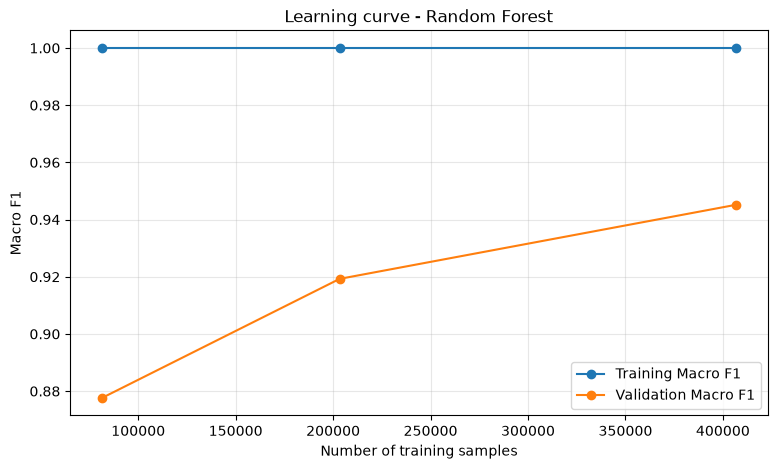

Generalization gaps:


,n_samples,generalization_gap
0,81341,0.12240
1,203354,0.08073
2,406708,0.05483


In [13]:

from sklearn.base import clone
from sklearn.model_selection import train_test_split

train_fractions = [0.2, 0.5, 1.0]
learning_results = []

for fraction in train_fractions:

    if fraction == 1.0:
        X_sub = X_train
        y_sub = y_train
    else:
        X_sub, _, y_sub, _ = train_test_split(
            X_train,
            y_train,
            train_size=fraction,
            stratify=y_train,
            random_state=42
        )

    # Recalculate class weights on the subset
    sub_classes, sub_counts = np.unique(
        y_sub, return_counts=True
    )

    alpha = float(best_params["alpha"])

    sub_weights = {
        c: (len(y_sub) / (len(sub_classes) * count)) ** alpha
        for c, count in zip(sub_classes, sub_counts)
    }

    model = clone(best_rf)
    model.set_params(
        class_weight=sub_weights if alpha > 0 else None
    )

    model.fit(X_sub, y_sub)

    train_pred = model.predict(X_sub)
    val_pred = model.predict(X_val)

    learning_results.append({
        "train_fraction": fraction,
        "n_samples": len(y_sub),
        "train_accuracy": accuracy_score(y_sub, train_pred),
        "val_accuracy": accuracy_score(y_val, val_pred),
        "train_macro_f1": f1_score(
            y_sub, train_pred, average="macro"
        ),
        "val_macro_f1": f1_score(
            y_val, val_pred, average="macro"
        )
    })

learning_df = pd.DataFrame(learning_results)

display(learning_df.round(5))

plt.figure(figsize=(9, 5))

plt.plot(
    learning_df["n_samples"],
    learning_df["train_macro_f1"],
    "o-",
    label="Training Macro F1"
)

plt.plot(
    learning_df["n_samples"],
    learning_df["val_macro_f1"],
    "o-",
    label="Validation Macro F1"
)

plt.xlabel("Number of training samples")
plt.ylabel("Macro F1")
plt.title("Learning curve - Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

learning_df["generalization_gap"] = (
    learning_df["train_macro_f1"]
    - learning_df["val_macro_f1"]
)

print("Generalization gaps:")
display(
    learning_df[
        ["n_samples", "generalization_gap"]
    ].round(5)
)


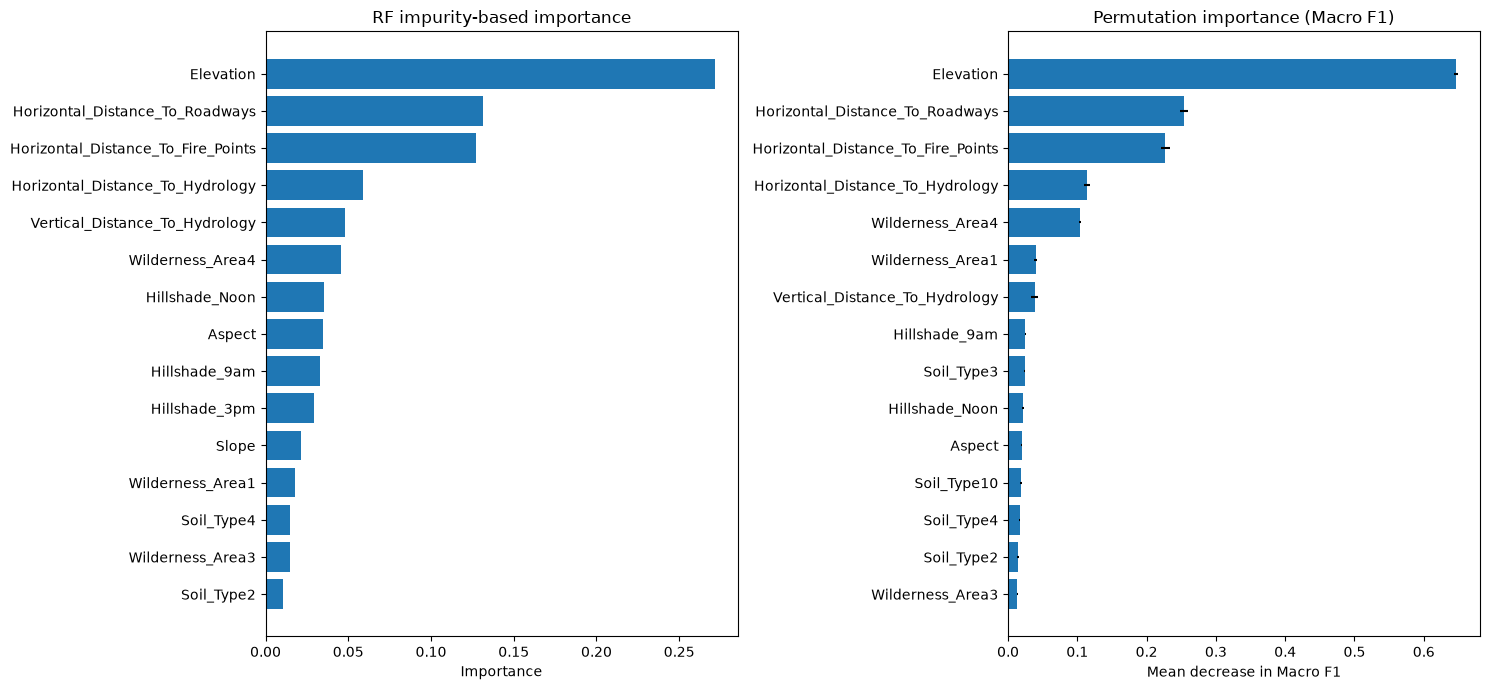

Native importance:


,feature,importance
0,Elevation,0.27164
5,Horizontal_Distance_To_Roadways,0.13114
9,Horizontal_Distance_To_Fire_Points,0.12728
3,Horizontal_Distance_To_Hydrology,0.05900
4,Vertical_Distance_To_Hydrology,0.04818
53,Wilderness_Area4,0.04566
7,Hillshade_Noon,0.03513
1,Aspect,0.03458
6,Hillshade_9am,0.03308
8,Hillshade_3pm,0.02920


Permutation importance:


,feature,importance_mean,importance_std
0,Elevation,0.64622,0.00250
5,Horizontal_Distance_To_Roadways,0.25373,0.00568
9,Horizontal_Distance_To_Fire_Points,0.22665,0.00652
3,Horizontal_Distance_To_Hydrology,0.11397,0.00393
53,Wilderness_Area4,0.10377,0.00093
10,Wilderness_Area1,0.04006,0.00228
4,Vertical_Distance_To_Hydrology,0.03837,0.00478
6,Hillshade_9am,0.02505,0.00098
13,Soil_Type3,0.02400,0.00057
7,Hillshade_Noon,0.02131,0.00125


In [14]:

from sklearn.inspection import permutation_importance

# Feature names
if hasattr(X_train, "columns"):
    feature_names = list(X_train.columns)
else:
    feature_names = [
        f"Feature_{i}" for i in range(X_train.shape[1])
    ]

# Native Random Forest feature importance
native_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": best_rf.feature_importances_
}).sort_values("importance", ascending=False)

# Stratified validation sample for permutation importance
X_perm, _, y_perm, _ = train_test_split(
    X_val,
    y_val,
    train_size=min(15000, len(y_val)),
    stratify=y_val,
    random_state=42
)

perm = permutation_importance(
    best_rf,
    X_perm,
    y_perm,
    scoring="f1_macro",
    n_repeats=3,
    random_state=42,
    n_jobs=1
)

permutation_df = pd.DataFrame({
    "feature": feature_names,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

top_native = native_importance.head(15).iloc[::-1]

axes[0].barh(
    top_native["feature"],
    top_native["importance"]
)
axes[0].set_title("RF impurity-based importance")
axes[0].set_xlabel("Importance")

top_perm = permutation_df.head(15).iloc[::-1]

axes[1].barh(
    top_perm["feature"],
    top_perm["importance_mean"],
    xerr=top_perm["importance_std"]
)
axes[1].set_title("Permutation importance (Macro F1)")
axes[1].set_xlabel("Mean decrease in Macro F1")

plt.tight_layout()
plt.show()

print("Native importance:")
display(native_importance.head(20).round(5))

print("Permutation importance:")
display(permutation_df.head(20).round(5))


,n_features,accuracy,macro_f1,train_time
0,5,0.94545,0.89670,12.25100
1,10,0.95950,0.93365,21.03784
2,20,0.96484,0.93934,26.72329
3,30,0.96620,0.94185,31.18587
4,40,0.96700,0.94380,33.70170
5,54,0.96717,0.94447,37.41736


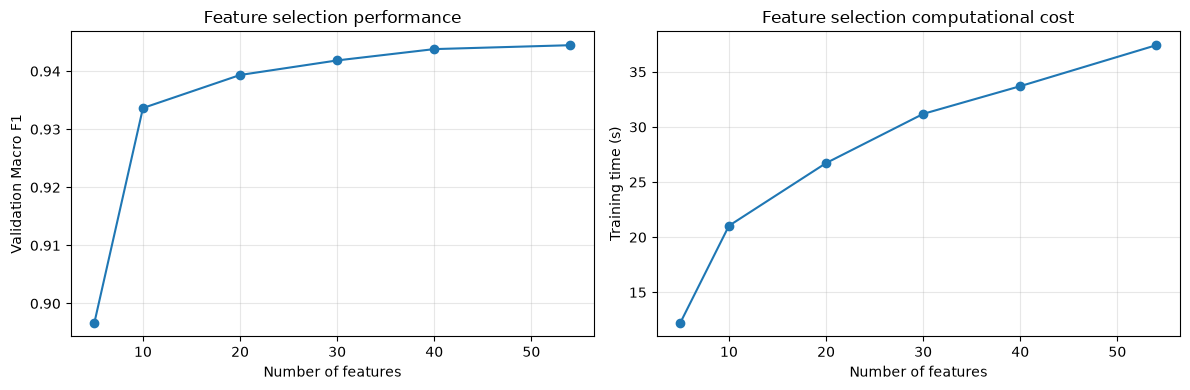

In [15]:

from sklearn.base import clone

feature_counts = [5, 10, 20, 30, 40, X_train.shape[1]]
feature_selection_results = []

# Feature ranking is obtained from training data only
ranked_features = native_importance["feature"].tolist()

for n_features in feature_counts:

    selected_features = ranked_features[:n_features]
    selected_indices = [
        feature_names.index(f) for f in selected_features
    ]

    # Works for both DataFrames and NumPy arrays
    if hasattr(X_train, "iloc"):
        X_tr = X_train.iloc[:, selected_indices]
        X_va = X_val.iloc[:, selected_indices]
    else:
        X_tr = X_train[:, selected_indices]
        X_va = X_val[:, selected_indices]

    model = clone(best_rf)

    start = perf_counter()
    model.fit(X_tr, y_train)
    train_time = perf_counter() - start

    predictions = model.predict(X_va)

    feature_selection_results.append({
        "n_features": n_features,
        "accuracy": accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val, predictions, average="macro"
        ),
        "train_time": train_time
    })

selection_df = pd.DataFrame(feature_selection_results)

display(selection_df.round(5))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    selection_df["n_features"],
    selection_df["macro_f1"],
    "o-"
)
axes[0].set_xlabel("Number of features")
axes[0].set_ylabel("Validation Macro F1")
axes[0].set_title("Feature selection performance")
axes[0].grid(alpha=0.3)

axes[1].plot(
    selection_df["n_features"],
    selection_df["train_time"],
    "o-"
)
axes[1].set_xlabel("Number of features")
axes[1].set_ylabel("Training time (s)")
axes[1].set_title("Feature selection computational cost")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


Classification report:
              precision    recall  f1-score   support

           1     0.9729    0.9607    0.9667     31776
           2     0.9688    0.9763    0.9725     42495
           3     0.9571    0.9683    0.9626      5363
           4     0.9138    0.9005    0.9071       412
           5     0.9052    0.8989    0.9020      1424
           6     0.9381    0.9374    0.9378      2605
           7     0.9636    0.9711    0.9673      3077

    accuracy                         0.9671     87152
   macro avg     0.9456    0.9447    0.9452     87152
weighted avg     0.9672    0.9671    0.9671     87152



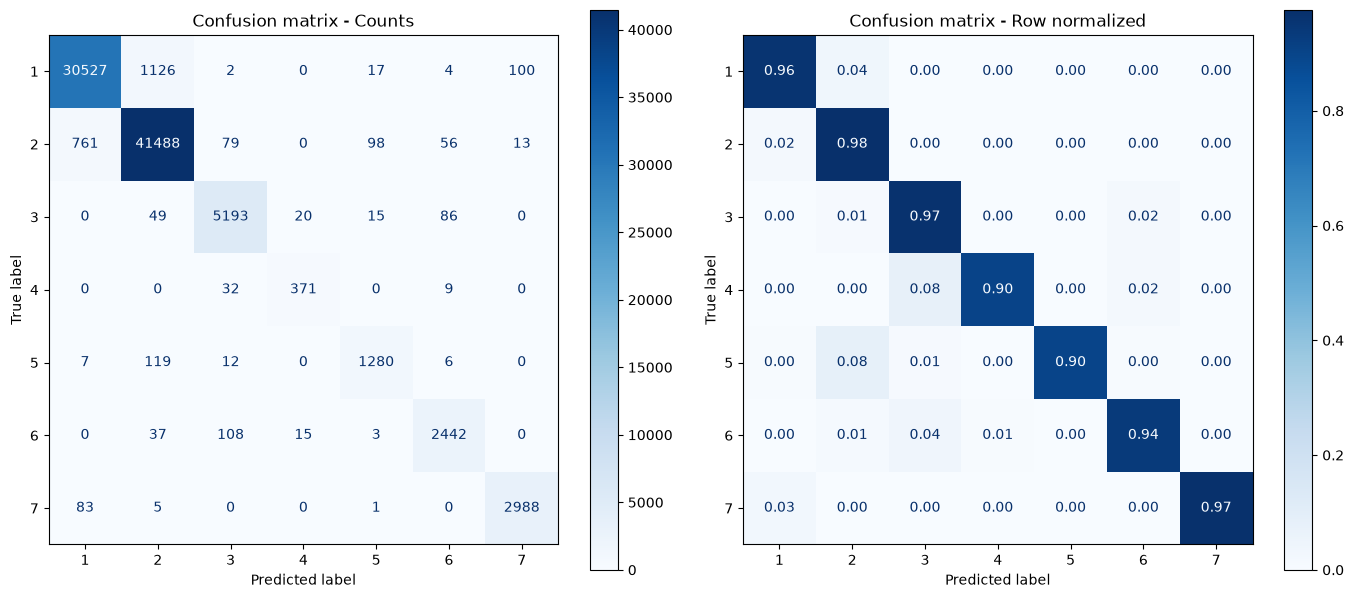

Top 15 most frequent confusions:


,true_class,predicted_class,errors,error_rate_within_class
0,1,2,1126,0.03544
6,2,1,761,0.01791
25,5,2,119,0.08357
32,6,3,108,0.04146
5,1,7,100,0.00315
9,2,5,98,0.00231
16,3,6,86,0.01604
36,7,1,83,0.02697
7,2,3,79,0.00186
10,2,6,56,0.00132


In [16]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_pred = best_rf.predict(X_val)

print("Classification report:")
print(classification_report(
    y_val, y_pred,
    digits=4,
    zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    ax=axes[0],
    cmap="Blues",
    values_format="d"
)
axes[0].set_title("Confusion matrix - Counts")

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    ax=axes[1],
    normalize="true",
    cmap="Blues",
    values_format=".2f"
)
axes[1].set_title("Confusion matrix - Row normalized")

plt.tight_layout()
plt.show()

# Identify the most frequent directional confusions
cm = confusion_matrix(
    y_val, y_pred, labels=classes
)

confusions = []

for i in range(len(classes)):
    for j in range(len(classes)):
        if i == j:
            continue

        confusions.append({
            "true_class": classes[i],
            "predicted_class": classes[j],
            "errors": cm[i, j],
            "error_rate_within_class": (
                cm[i, j] / cm[i].sum()
            )
        })

confusion_df = (
    pd.DataFrame(confusions)
    .sort_values("errors", ascending=False)
)

print("Top 15 most frequent confusions:")
display(confusion_df.head(15).round(5))


FINAL TEST RESULTS
------------------
Accuracy: 0.9696392509638333
Macro F1: 0.9485115706990203

Classification report:
              precision    recall  f1-score   support

           1     0.9726    0.9657    0.9692     31776
           2     0.9722    0.9771    0.9746     42495
           3     0.9564    0.9730    0.9646      5363
           4     0.9037    0.8883    0.8960       412
           5     0.9367    0.9143    0.9254      1424
           6     0.9504    0.9347    0.9425      2605
           7     0.9669    0.9678    0.9674      3077

    accuracy                         0.9696     87152
   macro avg     0.9513    0.9459    0.9485     87152
weighted avg     0.9696    0.9696    0.9696     87152



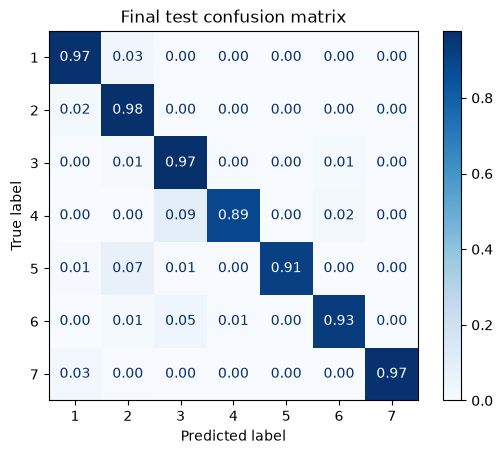

In [17]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Refit on training + validation
if hasattr(X_train, "iloc"):
    X_train_final = pd.concat(
        [X_train, X_val], axis=0
    )
else:
    X_train_final = np.concatenate(
        [X_train, X_val], axis=0
    )

y_train_final = np.concatenate([y_train, y_val])

# Recalculate weights on the combined dataset
final_classes = np.unique(y_train_final)

final_balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=final_classes,
    y=y_train_final
)

alpha = float(best_params["alpha"])

final_class_weights = (
    dict(zip(
        final_classes,
        final_balanced_weights ** alpha
    ))
    if alpha > 0 else None
)

final_rf = RandomForestClassifier(
    n_estimators=int(best_params["n_estimators"]),
    max_depth=None,
    min_samples_leaf=1,
    max_features=best_params["max_features"],
    class_weight=final_class_weights,
    random_state=42,
    n_jobs=-1
)

final_rf.fit(X_train_final, y_train_final)

# Test set: evaluate only after all choices are frozen
test_predictions = final_rf.predict(X_test)

print("FINAL TEST RESULTS")
print("------------------")
print(
    "Accuracy:",
    accuracy_score(y_test, test_predictions)
)
print(
    "Macro F1:",
    f1_score(y_test, test_predictions, average="macro")
)

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    digits=4,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    normalize="true",
    cmap="Blues",
    values_format=".2f"
)

plt.title("Final test confusion matrix")
plt.show()
